Chapter 4

In [1]:
# Setup: imports plus helper functions from Chapter 1 (Listings 1.5, 1.11) and Chapter 3 (Listing 3.28)
import numpy as np
import matplotlib.pyplot as plt
import itertools

def get_matching_event(event_condition, sample_space):
    return set([outcome for outcome in sample_space
                if event_condition(outcome)])

def compute_event_probability(event_condition, generic_sample_space):
    event = get_matching_event(event_condition, generic_sample_space)
    if type(generic_sample_space) == type(set()):
        return len(event) / len(generic_sample_space)
    event_size = sum(generic_sample_space[outcome]
                     for outcome in event)
    return event_size / sum(generic_sample_space.values())

def compute_high_confidence_interval(likelihoods, bin_width):
    peak_index = likelihoods.argmax()
    area = likelihoods[peak_index] * bin_width
    start_index, end_index = peak_index, peak_index + 1
    while area < 0.95:
        if start_index > 0:
            start_index -= 1
        if end_index < likelihoods.size - 1:
            end_index += 1
        area = likelihoods[start_index: end_index + 1].sum() * bin_width
    range_start, range_end = bin_edges[start_index], bin_edges[end_index]
    range_string = f"{range_start:.6f} - {range_end:.6f}"
    print((f"The frequency range {range_string} represents a "
           f"{100 * area:.2f}% confidence interval"))
    return start_index, end_index

1. What is the goal? How do we achieve it?
We want to know if we can win the red-card game more than half the time. We test a stopping strategy on shuffled decks, estimate win rates, and finally check every arrangement of a smaller deck.


In [2]:
# Listing 4.1 – Modeling a 52-card deck
red_cards = 26 * [1]
black_cards = 26 * [0]
unshuffled_deck = red_cards + black_cards

In [3]:
# Listing 4.2 – Shuffling a 52-card deck
np.random.seed(1)
shuffled_deck = np.random.permutation(unshuffled_deck)

In [4]:
# Listing 4.3 – Coding a card game strategy
remaining_red_cards = 26
for i, card in enumerate(shuffled_deck[:-1]):
    remaining_red_cards -= card
    remaining_total_cards = 52 - i - 1
    if remaining_red_cards / remaining_total_cards > 0.5:
        break

print(f"Stopping the game at index {i}.")
final_card = shuffled_deck[i + 1]
color = 'red' if final_card else 0
print(f"The next card in the deck is {'red' if final_card else 'black'}.")
print(f"We have {'won' if final_card else 'lost'}!")

Stopping the game at index 0.
The next card in the deck is red.
We have won!


2. What is the first strategy and how do we test it?
Stop after seeing a card when the fraction of red cards remaining is greater than 0.5, then use the next card as the final card. We shuffle and play many games to measure the win rate.

In [5]:
# Listing 4.4 – Generalizing the card game strategy
np.random.seed(0)
total_cards = 52
total_red_cards = 26
def execute_strategy(min_fraction_red=0.5, shuffled_deck=None,
                     return_index=False):
    if shuffled_deck is None:
        shuffled_deck = np.random.permutation(unshuffled_deck)

    remaining_red_cards = total_red_cards

    for i, card in enumerate(shuffled_deck[:-1]):
        remaining_red_cards -= card
        fraction_red_cards = remaining_red_cards / (total_cards - i - 1)
        if fraction_red_cards > min_fraction_red:
            break

    return (i+1, shuffled_deck[i+1]) if return_index else shuffled_deck[i+1]

In [6]:
# Listing 4.5 – Running the strategy over 1,000 shuffles
observations = np.array([execute_strategy() for _ in range(1000)])

In [7]:
# Listing 4.6 – Computing the frequency of wins
frequency_wins = observations.sum() / 1000
assert frequency_wins == observations.mean()
print(f"The frequency of wins is {frequency_wins}")

The frequency of wins is 0.511


In [8]:
# Listing 4.7 – Computing total profit
dollars_won = frequency_wins * 1000
dollars_lost = (1 - frequency_wins) * 1000
total_profit = dollars_won - dollars_lost
print(f"Total profit is ${total_profit:.2f}")

Total profit is $22.00


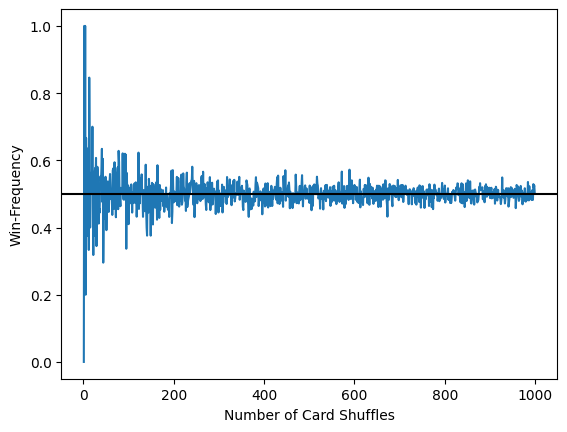

The win-frequency for 10,000 shuffles is 0.5035035035035035


In [9]:
# Listing 4.8 – Plotting simulated frequencies of wins (Figure 4.1)
np.random.seed(0)
def repeat_game(number_repeats):
    observations = np.array([execute_strategy()
                             for _ in range(number_repeats)])
    return observations.mean()

frequencies = []
for i in range(1, 1000):
    frequencies.append(repeat_game(i))

plt.plot(list(range(1, 1000)), frequencies)
plt.axhline(0.5, color='k')
plt.xlabel('Number of Card Shuffles')
plt.ylabel('Win-Frequency')
plt.show()
print(f"The win-frequency for 10,000 shuffles is {frequencies[-1]}")

3. What does the confidence interval say?
The first 1,000 games look promising, but a larger simulation gives an interval containing 0.5. The book's 3-million-shuffle run gives about 0.489–0.509. This does not show that the strategy is better than chance.



The frequency range 0.488938 - 0.509494 represents a 97.00% confidence interval


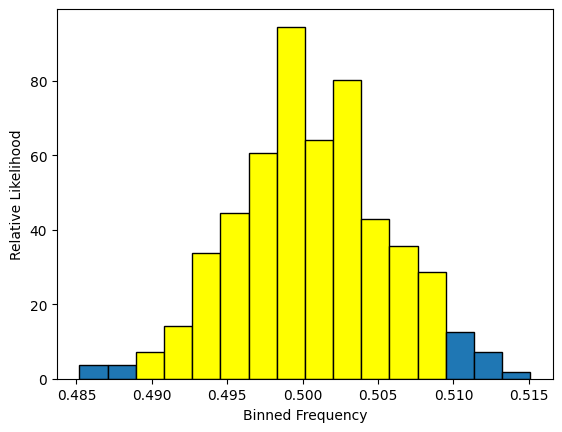

In [10]:
# Listing 4.9 – Computing the confidence interval for 3 million shuffles (Figure 4.2)
np.random.seed(0)
frequency_array = np.array([repeat_game(10000) for _ in range(300)])

likelihoods, bin_edges, patches = plt.hist(frequency_array, bins='auto',
                                           edgecolor='black', density=True)
bin_width = bin_edges[1] - bin_edges[0]
start_index, end_index = compute_high_confidence_interval(likelihoods,
                                                          bin_width)

for i in range(start_index, end_index):
    patches[i].set_facecolor('yellow')
plt.xlabel('Binned Frequency')
plt.ylabel('Relative Likelihood')
plt.show()

4. What is min_red_fraction? What range does it have?
It is the minimum fraction of remaining red cards needed to stop (the code uses greater than the threshold). A fraction is between 0 and 1. The book tests thresholds from 0.50 to 0.99 in steps of 0.01.

5. Should we run Listing 4.10?
Not for this lab. It simulates 150 million shuffles and the book warns that it takes about an hour. Its interval is approximately 0.4956–0.5043, still including 0.5. A smaller simulation is enough to demonstrate the idea.


# Listing 4.10 – Confidence interval for 150 million shuffles
# NOT RUN: the book warns this takes about an hour. Book result: 0.495601 - 0.504345 (96.03%).
# np.random.seed(0)
# frequency_array = np.array([repeat_game(50000) for _ in range(3000)])
# likelihoods, bin_edges = np.histogram(frequency_array, bins='auto',
#                                       density=True)
# bin_width = bin_edges[1] - bin_edges[0]
# compute_high_confidence_interval(likelihoods, bin_width)

# Listing 4.11 – Confidence interval for an updated strategy (min_red_fraction = 0.75)
# The book's version also takes about an hour (book result: 0.495535 - 0.504344, 96.43%).


6. Why switch to a 10-card deck?
It has only 252 distinct red/black orders, so we can compute the exact win probability instead of relying only on random samples.

In [11]:
# Listing 4.12 – Applying a basic strategy to a 10-card deck
total_cards = 10
total_red_cards = int(total_cards / 2)
total_black_cards = total_red_cards
unshuffled_deck = [1] * total_red_cards + [0] * total_black_cards
sample_space = set(itertools.permutations(unshuffled_deck))
win_condition = lambda x: execute_strategy(shuffled_deck=np.array(x))
prob_win = compute_event_probability(win_condition, sample_space)
print(f"Probability of a win is {prob_win}")

Probability of a win is 0.5


7. Explain Figure 4.3 and Listing 4.14.
Listing 4.14: The book checks decks of sizes 2, 4, 6, and 8 with different thresholds. Every tested strategy still has a 50% win rate.

Figure 4.3: It separates outcomes into four groups: stop and win (A), stop and lose (B), do not stop and win (C), and do not stop and lose (D). As the threshold increases, stopping and winning becomes less common, but not stopping and winning becomes more common. A + C stays near 0.5. This explains why changing the threshold does not help.

In [12]:
# Listing 4.13 – Applying multiple strategies to a 10-card deck
def scan_strategies():
    fractions = [value / 100 for value in range(50, 100)]
    probabilities = []
    for frac in fractions:
        win_condition = lambda x: execute_strategy(frac,
                                                   shuffled_deck=np.array(x))
        probabilities.append(compute_event_probability(win_condition,
                                                       sample_space))
    return probabilities

probabilities = scan_strategies()
print(f"Lowest probability of win is {min(probabilities)}")
print(f"Highest probability of win is {max(probabilities)}")

Lowest probability of win is 0.5
Highest probability of win is 0.5


In [13]:
# Listing 4.14 – Applying multiple strategies to multiple decks
for total_cards in [2, 4, 6, 8]:
    total_red_cards = int(total_cards / 2)
    total_black_cards = total_red_cards
    unshuffled_deck = [1] * total_red_cards + [0] * total_black_cards

    sample_space = set(itertools.permutations(unshuffled_deck))
    probabilities = scan_strategies()
    if all(prob == 0.5 for prob in probabilities):
        print(f"No winning strategy found for deck of size {total_cards}")
    else:
        print(f"Winning strategy found for deck of size {total_cards}")

No winning strategy found for deck of size 2
No winning strategy found for deck of size 4
No winning strategy found for deck of size 6
No winning strategy found for deck of size 8


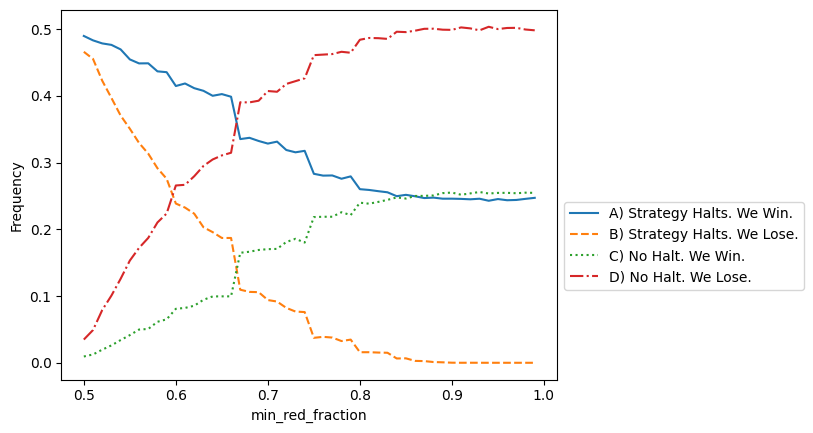

In [14]:
# Listing 4.15 – Plotting strategy outcomes across a 52-card deck (Figure 4.3)
np.random.seed(0)
total_cards = 52
total_red_cards = 26
unshuffled_deck = red_cards + black_cards

def repeat_game_detailed(number_repeats, min_red_fraction):
    observations = [execute_strategy(min_red_fraction, return_index=True)
                    for _ in range(num_repeats)]
    successes = [index for index, card, in observations if card == 1]
    halt_success = len([index for index in successes if index != 51])
    no_halt_success = len(successes) - halt_success

    failures = [index for index, card, in observations if card == 0]
    halt_failure = len([index for index in failures if index != 51])
    no_halt_failure = len(failures) - halt_failure
    result = [halt_success, halt_failure, no_halt_success, no_halt_failure]
    return [r / number_repeats for r in result]

fractions = [value / 100 for value in range(50, 100)]
num_repeats = 50000
result_types = [[], [], [], []]
for fraction in fractions:
    result = repeat_game_detailed(num_repeats, fraction)
    for i in range(4):
        result_types[i].append(result[i])

plt.plot(fractions, result_types[0],
         label='A) Strategy Halts. We Win.')
plt.plot(fractions, result_types[1], linestyle='--',
         label='B) Strategy Halts. We Lose.')
plt.plot(fractions, result_types[2], linestyle=':',
         label='C) No Halt. We Win.')
plt.plot(fractions, result_types[3], linestyle='-.',
         label='D) No Halt. We Lose.')
plt.xlabel('min_red_fraction')
plt.ylabel('Frequency')
plt.legend(bbox_to_anchor=(1.0, 0.5))
plt.show()

8. What is mathematical induction? Is it used here?
Induction proves a claim for every positive integer by proving a starting case and showing that one case implies the next. The book does not give a formal induction proof here. It tests several small even-sized decks and then extrapolates the pattern. This supports the conclusion but is not a complete induction argument.
9. What is the conclusion of Case Study 1?
There is no stopping strategy that improves the 50% chance of winning when the deck is randomly shuffled with equal numbers of red and black cards. The simplest optimal choice is to take the first card. We should not assume a strategy is better just because it sounds logical.

In [15]:
# Listing 4.16 – The optimal winning strategy
def optimal_strategy(shuffled_deck):
    return shuffled_deck[0]

np.random.seed(0)
print(np.mean([optimal_strategy(np.random.permutation(unshuffled_deck)) for _ in range(10000)]))

0.5002


Case Study 1 summary Chapters 1–4
What we did: We studied the red-card game and tested whether choosing when to stop could improve our chance of winning.

Tools we used: Python probability calculations, sample spaces, Matplotlib graphs, NumPy random simulations, histograms, confidence intervals, and permutations.

What I learned and how: Chapter 1 taught me how to calculate probabilities; Chapter 2 showed me how to plot them; Chapter 3 showed me how to simulate events and measure uncertainty; Chapter 4 tested the game strategy and checked the exact small-deck outcomes. The final result is 50%, so stopping at a special time does not give an advantage.